# **Profit or Planet**  
### As the companies make more money, do they care more about the society and sustainability? 


It is obvious as we do business, we need profit and revenue inorder to grow and pay the fixed costs. But for big companies who have enough money , are they focusing on their growth, profitbailtiy or what they can do to the society? 

Questions:
- How do financial and ESG indicators correlate for major UK energy firms?
- Can we classify companies as profit-focused or sustainability-focused based on their data?
- Which companies show a balanced profile (profit + ESG performance)?
- Has this balance shifted over time (2015–2025)?
- What's better for the long term position of the company? Profitability ??? or Sustainabiltiy 


Companies that will be asses in this projects are include Shell and BP (Oil & Gas firm), Rolls-Royce Holdings plc (mainly aero engines, and developing small modular nuclear reactors), SSE (wind power and electricity networks), Centrica (gas and energy supply, owner of British Gas) and Drax (biomass power), with ExxonMobil as a US oil major for comparison.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

START, END = "2015-10-11", "2026-10-31"
DATA_DIR = Path("data")
FIG_DIR = Path("figures/profit_planet")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Save the current figure as a PNG so the README can show it."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def cached_close(tickers, cache_file):
    """Daily closes from Yahoo, saved to data/ on the first run so later runs don't depend on Yahoo."""
    cache_file = DATA_DIR / cache_file
    if cache_file.exists():
        return pd.read_csv(cache_file, index_col=0, parse_dates=True)
    px = yf.download(tickers, start=START, end=END, progress=False)["Close"]
    px.to_csv(cache_file)
    return px


tickers = ["BP", "SHEL", "XOM", "CNA.L", "RR.L", "SSE.L", "DRX.L"]
prices = cached_close(tickers, "profit_planet_prices.csv")   # Work with just closing prices

## Clean and Check for missing values
prices = prices.ffill().dropna()

prices.tail()


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


,BP,CNA.L,DRX.L,RR.L,SHEL,SSE.L,XOM
Date,,,,,,,
2026-10-26,50.529999,149.850006,807.0,1234.800049,106.910004,2485.0,184.539993
2026-10-27,48.930000,150.449997,811.0,1242.400024,104.779999,2490.0,179.910004
2026-10-28,49.790001,156.199997,818.5,1263.000000,105.190002,2604.0,182.020004
2026-10-29,50.349998,155.699997,823.0,1280.000000,107.669998,2647.0,183.289993
2026-10-30,50.389999,152.699997,808.0,1239.400024,108.690002,2627.0,187.250000


## **Return and Volatility** 

In [2]:
returns = prices.pct_change()
annual_returns = returns.mean() * 252
annual_volatility = returns.std() * np.sqrt(252)

market_summary = pd.DataFrame({'Annual Return': annual_returns, 'Volatility': annual_volatility})
market_summary.sort_values(by='Annual Return', ascending=False)

,Annual Return,Volatility
RR.L,0.251854,0.474400
XOM,0.155387,0.275073
DRX.L,0.154599,0.351621
SHEL,0.152532,0.296023
BP,0.136315,0.310332
SSE.L,0.078498,0.248886
CNA.L,0.014367,0.325264


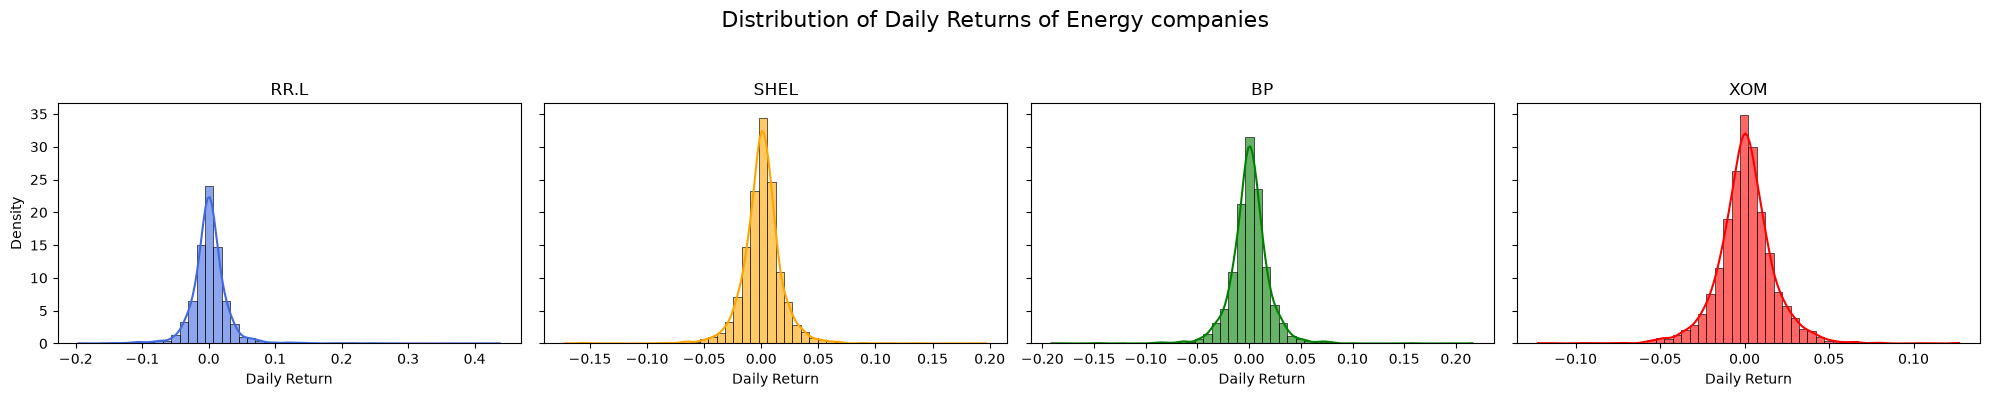

In [3]:
tickers_to_plot = ['RR.L', 'SHEL', 'BP', 'XOM']
colors = ['royalblue', 'orange', 'green', 'red']

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)

for ax, ticker, color in zip(axes, tickers_to_plot, colors):
    sns.histplot(returns[ticker].dropna(), bins=50, kde=True, color=color, ax=ax, stat='density', alpha=0.6)
    ax.set_title(ticker)
    ax.set_xlabel("Daily Return")
    if ax == axes[0]:
        ax.set_ylabel("Density")
    else:
        ax.set_ylabel("")

plt.suptitle("Distribution of Daily Returns of Energy companies", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.93])
save_fig("01_return_distributions")
plt.show()

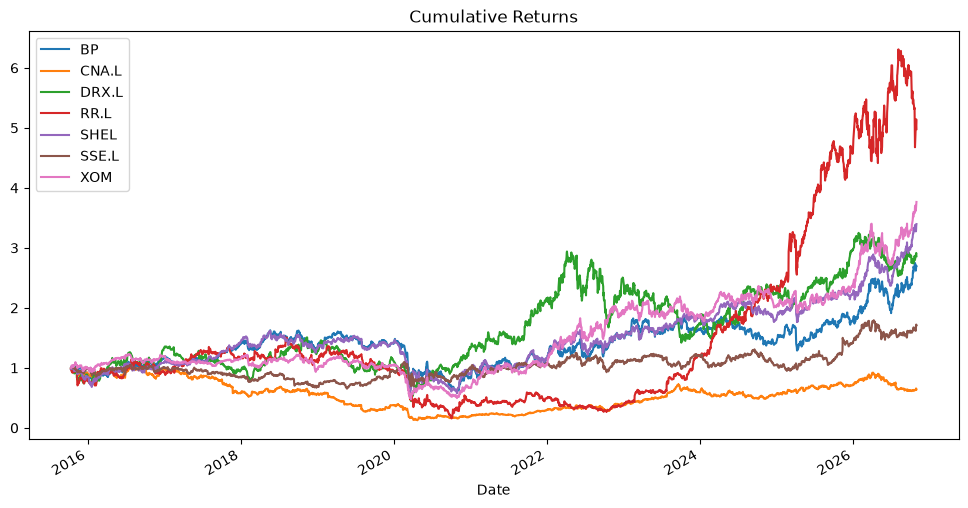

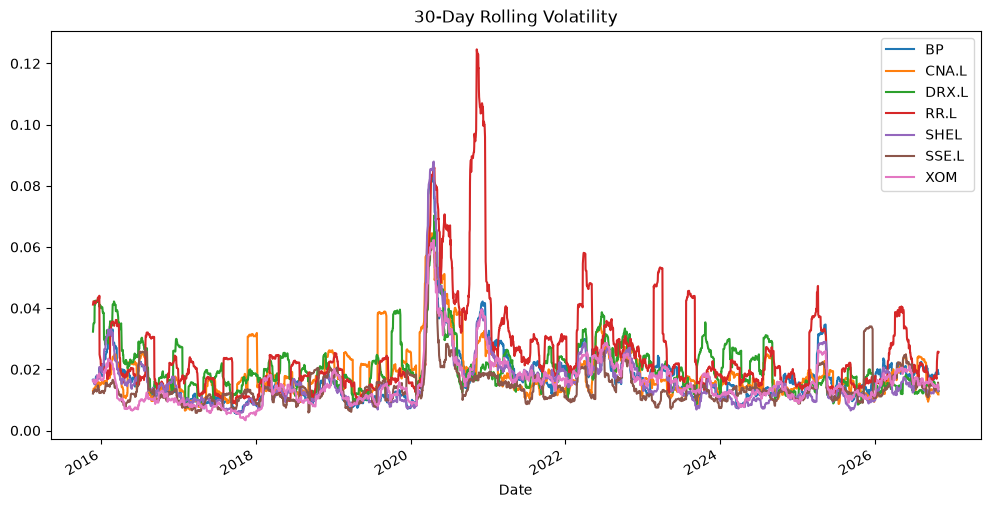

In [4]:
# Cumulative returns
Cumulative_Return = (1 + returns).cumprod()

# Cumulative returns
Cumulative_Return.plot(figsize=(12,6), title="Cumulative Returns")
save_fig("02_cumulative_returns")
plt.show()

Volatility = returns.rolling(window=30).std()

Volatility .plot(figsize=(12,6), title="30-Day Rolling Volatility")
save_fig("03_rolling_volatility")
plt.show()

## **Financial Statement analysis**

In [5]:
# Latest annual report for each company. The raw items are saved to data/ on the first run,
# so the numbers don't change every time Yahoo moves on to a newer report.
oil_compa = ["BP", "SHEL", "XOM"]
alter_ener = ["CNA.L", "RR.L", "SSE.L", "DRX.L"]
FIN_CACHE = DATA_DIR / "profit_planet_financials.csv"


def latest_statements(t):
    """Items needed for the ratios, from the most recent annual income statement, balance sheet and cash flow."""
    ticker = yf.Ticker(t)
    fin, bal, cash = ticker.financials, ticker.balance_sheet, ticker.cashflow
    return {
        "Fiscal year end": fin.columns[0].date(),
        "Currency": ticker.info.get("financialCurrency"),
        "Revenue": fin.loc["Total Revenue"].iloc[0],
        "Operating Income": fin.loc["Operating Income"].iloc[0],
        "Net Income": fin.loc["Net Income"].iloc[0],
        "Gross Profit": fin.loc["Gross Profit"].iloc[0],
        "Total Assets": bal.loc["Total Assets"].iloc[0],
        "Liabilities": bal.loc["Total Liabilities Net Minority Interest"].iloc[0],
        "Equity": bal.loc["Stockholders Equity"].iloc[0],
        "Capital Expenditure": cash.loc["Capital Expenditure"].iloc[0],
        "Operating Cash Flow": cash.loc["Operating Cash Flow"].iloc[0],
    }


if FIN_CACHE.exists():
    statements = pd.read_csv(FIN_CACHE, index_col=0)
else:
    statements = pd.DataFrame({t: latest_statements(t) for t in oil_compa + alter_ener}).T
    statements.to_csv(FIN_CACHE)
amounts = statements.drop(columns=["Fiscal year end", "Currency"]).apply(pd.to_numeric)


def ratios(s):
    """Margins and ratios from the raw items (amounts in billions of the reporting currency)."""
    return pd.DataFrame({
        "Revenue (B$)": s["Revenue"] / 1e9,
        "Operating Margin (%)": s["Operating Income"] / s["Revenue"] * 100,  # Operating profit margin
        "Net Margin (%)": s["Net Income"] / s["Revenue"] * 100,              # Net profit margin
        "Gross Margin (%)": s["Gross Profit"] / s["Revenue"] * 100,          # Gross profit margin
        "ROE (%)": s["Net Income"] / s["Equity"] * 100,                      # Return on Equity
        "Debt-to-Equity": s["Liabilities"] / s["Equity"],                    # total liabilities / equity
        "Total Assets (B$)": s["Total Assets"] / 1e9,
        # Free Cash Flow: yfinance reports capital expenditure as a negative number, so it is added
        "Free Cash Flow (B$)": (s["Operating Cash Flow"] + s["Capital Expenditure"]) / 1e9,
    }).round(2)


print(statements[["Fiscal year end", "Currency"]].to_string())
fin_df = ratios(amounts.loc[oil_compa])
fin_df


      Fiscal year end Currency
BP         2025-12-31      USD
SHEL       2025-12-31      USD
XOM        2025-12-31      USD
CNA.L      2025-12-31      GBP
RR.L       2025-12-31      GBP
SSE.L      2026-03-31      GBP
DRX.L      2025-12-31      GBP


,Revenue (B$),Operating Margin (%),Net Margin (%),Gross Margin (%),ROE (%),Debt-to-Equity,Total Assets (B$),Free Cash Flow (B$)
BP,189.34,8.35,0.03,17.71,0.10,3.86,278.53,11.27
SHEL,266.89,10.33,6.68,15.92,10.23,1.12,370.35,23.92
XOM,323.90,10.48,8.91,21.99,11.12,0.70,448.98,23.61


In [6]:
fin_df_alter_uk = ratios(amounts.loc[alter_ener])
fin_df_alter_uk


,Revenue (B$),Operating Margin (%),Net Margin (%),Gross Margin (%),ROE (%),Debt-to-Equity,Total Assets (B$),Free Cash Flow (B$)
CNA.L,19.49,3.96,-0.37,14.52,-2.33,3.86,15.42,0.14
RR.L,21.21,20.80,27.54,29.12,214.27,12.97,38.12,3.58
SSE.L,10.19,19.56,11.87,37.05,7.72,1.21,35.35,-1.01
DRX.L,5.39,11.72,1.35,28.07,4.26,1.62,4.50,0.52


### Converting to US dollars

The UK companies report in pounds, so revenue, assets and free cash flow are converted at the average GBP→USD rate over each company's own fiscal year. The ratios don't need converting.


In [7]:
# Convert GBP amounts to USD at the average rate over each company's fiscal year
assert (statements.loc[alter_ener, "Currency"] == "GBP").all()
gbpusd = cached_close("GBPUSD=X", "gbpusd.csv").squeeze()

cols_to_convert = ["Revenue (B$)", "Total Assets (B$)", "Free Cash Flow (B$)"]
for t in alter_ener:
    fy_end = pd.Timestamp(statements.loc[t, "Fiscal year end"])
    rate = gbpusd.loc[fy_end - pd.DateOffset(years=1) : fy_end].mean()
    fin_df_alter_uk.loc[t, cols_to_convert] = (fin_df_alter_uk.loc[t, cols_to_convert] * rate).round(2)
    print(f"{t}: £1 = ${rate:.3f} (average over the year to {fy_end.date()})")

fin_df_alter_uk


CNA.L: £1 = $1.319 (average over the year to 2025-12-31)
RR.L: £1 = $1.319 (average over the year to 2025-12-31)
SSE.L: £1 = $1.340 (average over the year to 2026-03-31)
DRX.L: £1 = $1.319 (average over the year to 2025-12-31)


,Revenue (B$),Operating Margin (%),Net Margin (%),Gross Margin (%),ROE (%),Debt-to-Equity,Total Assets (B$),Free Cash Flow (B$)
CNA.L,25.70,3.96,-0.37,14.52,-2.33,3.86,20.33,0.18
RR.L,27.97,20.80,27.54,29.12,214.27,12.97,50.26,4.72
SSE.L,13.66,19.56,11.87,37.05,7.72,1.21,47.38,-1.35
DRX.L,7.11,11.72,1.35,28.07,4.26,1.62,5.93,0.69


- Operating Margin -> how efficient core operations are
- Net Margin -> profitability after all expenses
- ROE -> how well equity is generating profits
- Debt-to-Equity -> leverage (risk structure)
- Asset Turnover -> how effectively assets generate revenue


Cash flow statement 
- Operating activities → cash generated from day-to-day business
- Investing activities → cash spent on growth (e.g., new equipment, acquisitions) 
- Financing activities → cash from or to investors (e.g., debt, dividends, buybacks)


## **Financial Comparison** 
Comparing Revenue, Total Assets and Free Cash Flow 

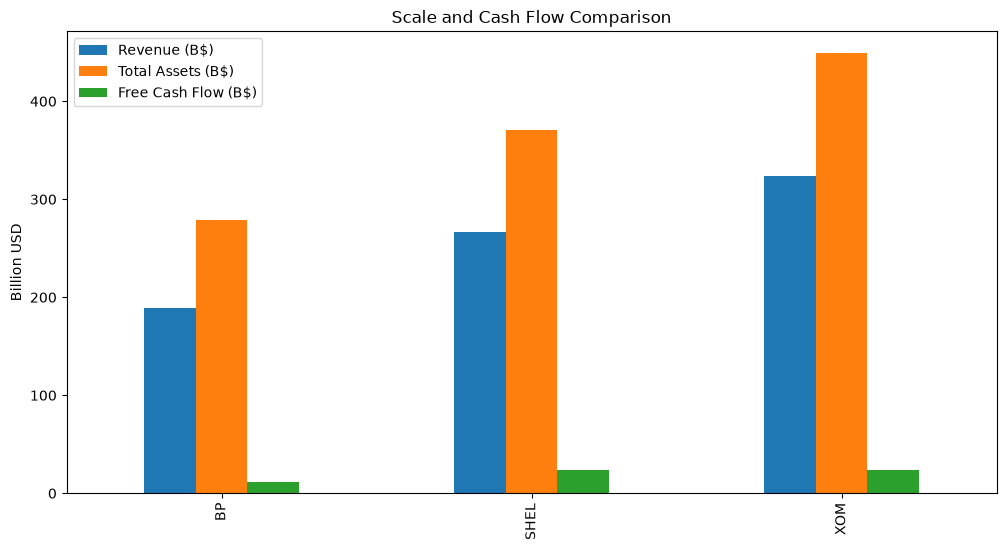

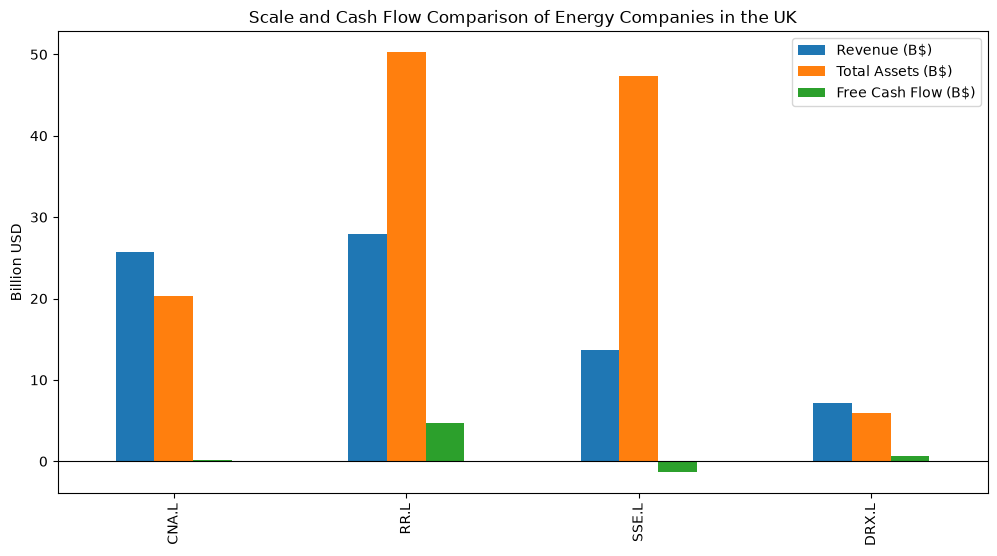

In [8]:
fin_df[['Revenue (B$)', 'Total Assets (B$)', 'Free Cash Flow (B$)']].plot(kind='bar', figsize=(12,6))
plt.title('Scale and Cash Flow Comparison')
plt.ylabel('Billion USD')
save_fig("04_scale_oil_majors")
plt.show()

fin_df_alter_uk[['Revenue (B$)', 'Total Assets (B$)', 'Free Cash Flow (B$)']].plot(kind='bar', figsize=(12,6))
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Scale and Cash Flow Comparison of Energy Companies in the UK')
plt.ylabel('Billion USD')
save_fig("05_scale_uk")
plt.show()


ExxonMobil has the highest revenue and assets, followed by Shell and BP, reflecting their company sizes. Shell and ExxonMobil generate similar free cash flow (about $24B each), while BP's is less than half of that.

Among the UK-based companies, Rolls-Royce has the highest free cash flow. **SSE's free cash flow is negative**: it is spending more on new electricity networks and wind farms than its operations bring in, and it has the most assets compared to its revenue. This is what investing in the energy transition looks like on a cash flow statement.

**Note:** these figures come from each company's latest annual report (FY2025; SSE's year ends March 2026).


## **Profitability Comparison** 
Assessing Profitability ratios, all of the companies can be compared together because the ratio metrics are currecies independent 

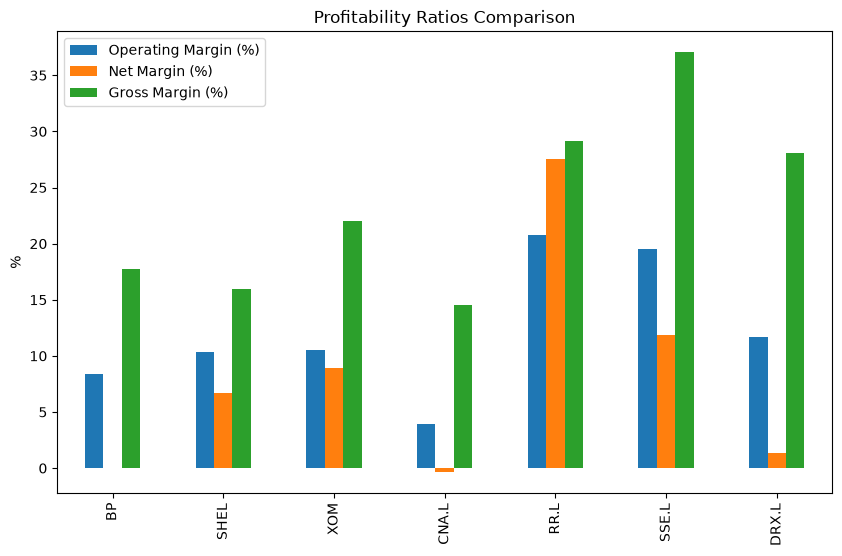

In [9]:
# Select the columns you want from each DataFrame
cols = ['Operating Margin (%)', 'Net Margin (%)', 'ROE (%)', 'Gross Margin (%)','Debt-to-Equity']

# Combine the selected columns from both DataFrames
combined_df = pd.concat([fin_df[cols], fin_df_alter_uk[cols]])


combined_df[['Operating Margin (%)', 'Net Margin (%)', 'Gross Margin (%)']].plot(kind='bar', figsize=(10,6))
plt.title('Profitability Ratios Comparison')
plt.ylabel('%')
save_fig("06_profitability")
plt.show()

Centrica has the lowest margins, with a small net loss in 2025. Among the oil majors, BP has the lowest net margin (almost zero) despite its size. SSE has the highest gross margin and Rolls-Royce the highest operating and net margins.


## **Evaluating Risk**

RR.L’s ROE (over 200%) and Debt-to-Equity (about 13) are extreme because its shareholders’ equity has only just turned positive after years of being negative, following pandemic losses and restructuring. Dividing by such a small equity gives huge ratios, so they are not directly comparable with other firms.

Rolls-Royce Holdings plc (RR.L) has had negative shareholder equity, which occurred when its liabilities exceeded its assets, largely due to the costs from engine problems (specifically the Trent 1000 engine) and accounting changes. However, the company has been working to improve its financial situation through cost reductions and operational restructuring. The company's financial performance has improved, with increased operating profit and free cash flow. This has led to a positive outlook for investors, and the company plans to reintroduce dividends. A company with negative equity owes more than it owns, a situation that can be risky. However, improvements in operational efficiency and cash flow indicate a turnaround is underway, making the situation less critical than it was previously.





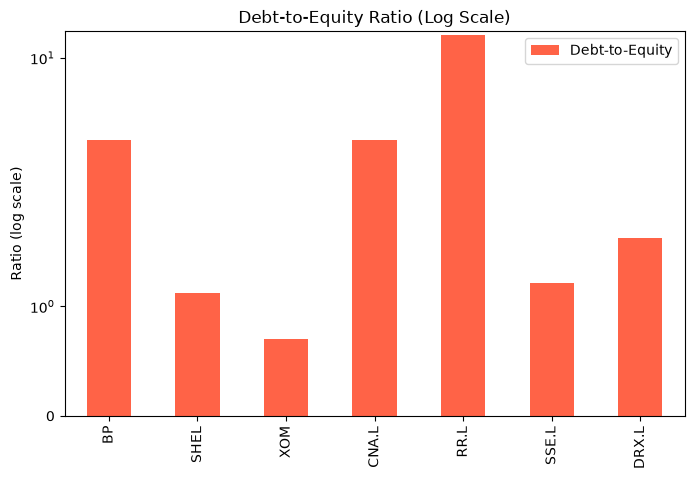

In [10]:
combined_df[['Debt-to-Equity']].plot(kind='bar', color='tomato', figsize=(8,5))
plt.yscale('symlog')  # handles both positive and negative values
plt.title('Debt-to-Equity Ratio (Log Scale)')
plt.ylabel('Ratio (log scale)')
plt.legend()
save_fig("07_debt_to_equity")
plt.show()

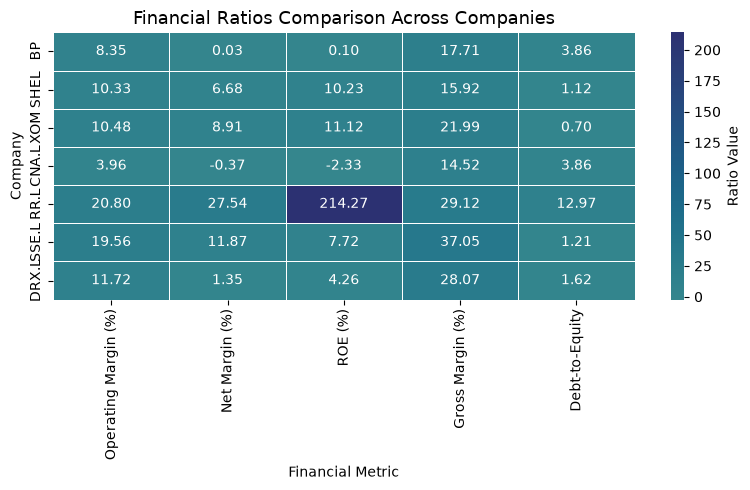

In [11]:
plt.figure(figsize=(8,5))
sns.heatmap(combined_df, annot=True, fmt=".2f", cmap='crest', center=0,
            linewidths=0.5, cbar_kws={'label': 'Ratio Value'})
plt.title('Financial Ratios Comparison Across Companies', fontsize=13)
plt.ylabel('Company')
plt.xlabel('Financial Metric')
plt.tight_layout()
save_fig("08_ratio_heatmap")
plt.show()

# *How sustainable are they?*

Financial analysis and metrics on the above section demonstrate the performance of the companies, but have you ever wonder, if these companies become more responsible to the world as they perform better or generate more profit?  

This section will analyse how sustainability they are and if they put more investment in attempting reducing carbon emissions


In [12]:
# ESG Risk scores (Sustainalytics, as shown on Yahoo Finance). Yahoo stopped serving them in 2026
# (the request now returns HTTP 404), so the scores from the last run that worked (October 2026) are kept in data/.
esg_df = pd.read_csv(DATA_DIR / "profit_planet_esg.csv", index_col=0)

combined_full = combined_df.merge(esg_df, left_index=True, right_index=True, how='left')
combined_full


,Operating Margin (%),Net Margin (%),ROE (%),Gross Margin (%),Debt-to-Equity,totalEsg,environmentScore,socialScore,governanceScore
BP,8.35,0.03,0.10,17.71,3.86,30.44,18.19,9.81,2.44
SHEL,10.33,6.68,10.23,15.92,1.12,31.11,21.25,7.83,2.03
XOM,10.48,8.91,11.12,21.99,0.70,39.97,24.79,10.27,4.91
CNA.L,3.96,-0.37,-2.33,14.52,3.86,24.86,10.17,12.30,2.39
RR.L,20.80,27.54,214.27,29.12,12.97,25.78,9.47,13.24,3.07
SSE.L,19.56,11.87,7.72,37.05,1.21,20.93,7.40,12.25,1.29
DRX.L,11.72,1.35,4.26,28.07,1.62,20.68,9.26,9.23,2.19


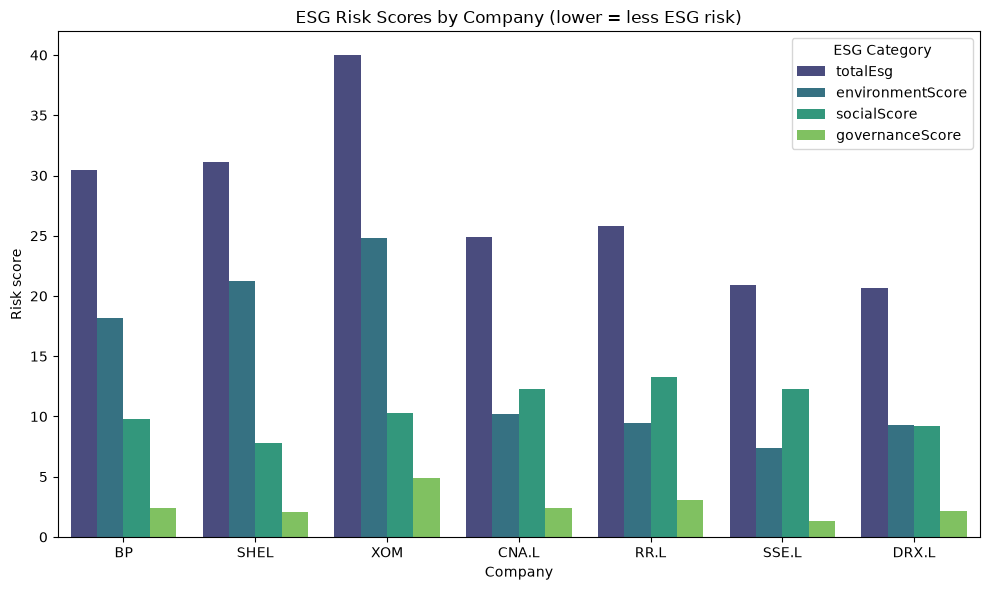

In [13]:
# Select ESG-related columns
esg_cols = ['totalEsg', 'environmentScore', 'socialScore', 'governanceScore']

# Reshape (melt) for easier plotting
esg_melt = combined_full[esg_cols].reset_index().melt(id_vars='index', var_name='Category', value_name='Score')
esg_melt.rename(columns={'index': 'Company'}, inplace=True)

plt.figure(figsize=(10,6))
sns.barplot(x='Company', y='Score', hue='Category', data=esg_melt, palette='viridis')
plt.title('ESG Risk Scores by Company (lower = less ESG risk)')
plt.ylabel('Risk score')
plt.xlabel('Company')
plt.legend(title='ESG Category')
plt.tight_layout()
save_fig("09_esg_risk_scores")
plt.show()

### **Reading the ESG scores**

These are **ESG Risk** scores from Sustainalytics: they measure how exposed a company is to environmental, social and governance risks that it isn't managing. **Lower is better.** Below 20 counts as low risk, 20–30 as medium and 30–40 as high.

### **Does more profit come with lower ESG risk?**

With only 7 companies, a statistical model can't be trusted (a random forest tried in an earlier version scored R² = −11.8, worse than guessing the average). So the comparison is a simple scatter plot and a rank correlation.


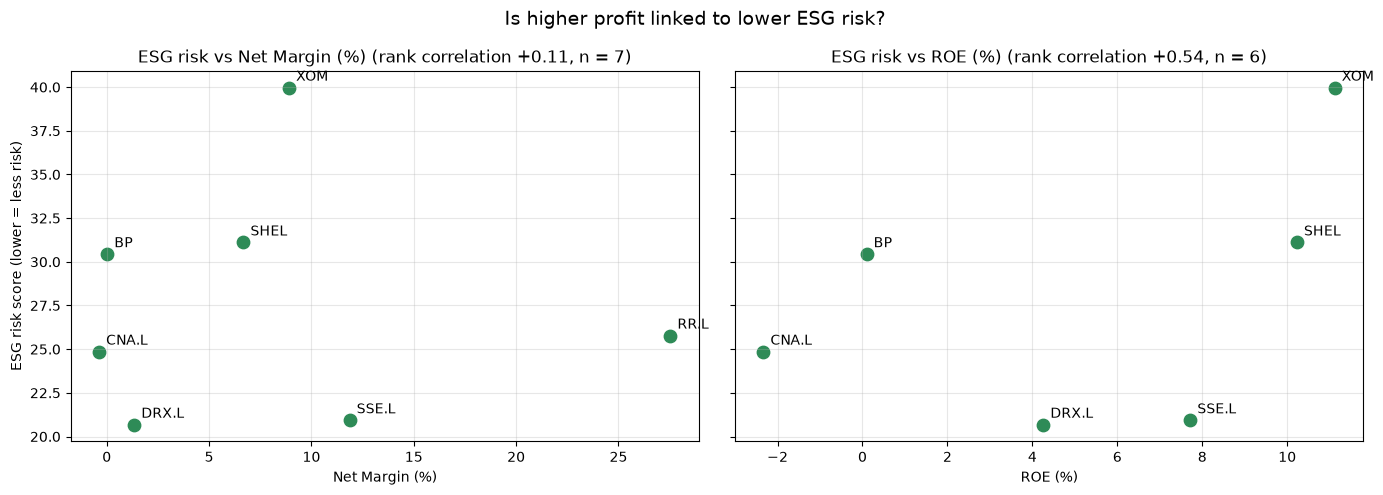

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric in zip(axes, ["Net Margin (%)", "ROE (%)"]):
    # Rolls-Royce's equity has only just turned positive, so its ROE isn't meaningful and is left out of the ROE panel
    data = combined_full if metric == "Net Margin (%)" else combined_full.drop(index="RR.L")
    ax.scatter(data[metric], data["totalEsg"], s=80, color="seagreen")
    for company, row in data.iterrows():
        ax.annotate(company, (row[metric], row["totalEsg"]), xytext=(5, 5), textcoords="offset points")
    rho = data[metric].corr(data["totalEsg"], method="spearman")
    ax.set_title(f"ESG risk vs {metric} (rank correlation {rho:+.2f}, n = {len(data)})", fontsize=12)
    ax.set_xlabel(metric)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("ESG risk score (lower = less risk)")
fig.suptitle("Is higher profit linked to lower ESG risk?", fontsize=14)
plt.tight_layout()
save_fig("10_esg_vs_profit")
plt.show()


# **Conclusion**

**More profit does not come with lower ESG risk.** The rank correlation between ESG risk and profit is weak and, if anything, positive: +0.11 for net margin and +0.54 for ROE. The more profitable firms carry *more* ESG risk, although with 6–7 companies this can't be called a real relationship.

**What separates the companies is their business, not their profit.**
- **Oil and gas majors** (ExxonMobil 40.0, Shell 31.1, BP 30.4) are high risk, mostly because of their environment scores (18–25).
- **UK power companies** (Drax 20.7, SSE 20.9, Centrica 24.9) and Rolls-Royce (25.8) are medium risk, with environment scores of 7–10.

**Answers to the questions:**
- **Profit-focused:** ExxonMobil and Shell have the strongest returns on equity among the large firms and the highest ESG risk.
- **Balanced:** **SSE** has a solid 11.9% net margin and nearly the lowest ESG risk (20.9). But its free cash flow is negative because it is building networks and wind farms, so the transition costs it cash today.
- **Has the balance shifted over 2015–2025?** This can't be answered with this data. Yahoo only ever gave a current ESG snapshot, and it has now stopped serving ESG data altogether. Historical ESG ratings would need a paid provider.
- **What is better for the long term?** So far, the market has not rewarded lower ESG risk. From October 2015 to October 2026, the oil majors returned 14–16% a year against 8% for SSE and 1% for Centrica (average annual return of daily prices). Rolls-Royce was the best performer at 25% a year after its turnaround.

**Limitations:** one year of financial statements, a single ESG snapshot, and seven companies. The results describe these companies, not energy companies in general.
